# A brief tutorial 

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pynav.agents import AdaBCKAgent
from pynav.environment import Environment
from pynav.q_functions import TabularQ
from pynav.fmap import FMap
from pynav.stepsize import StepSize

from math import isfinite

## Data Loading

In [2]:
data = np.load("/storage/rando/data/nose_data.npy")
n_thr = 3e-6 

data[data < n_thr] = 0.0

data = np.swapaxes(data, 0, 2)

We can instantiate the an agent as follows

In [52]:
thresholds = [
    np.array([0.33, 0.66]), # intermittency
    np.zeros(4) # intensity
]

fmap = FMap(thresholds=thresholds)

env = Environment(
    data = data,
    n_thr = n_thr,
    init_position = np.array([0, 0, 0]),
    terminal_position = np.array([20, 142]),
    velocity = 10,
    random_time = False
)

agent = AdaBCKAgent(
    env = env,
    q_function = TabularQ((3, 5, 4)),
    fmap = fmap,
    memory = 50,
    gamma = 0.999,
    epsilon = StepSize(mode='sqrt', init_value=0.1, decay=1e-1), 
    alpha = StepSize(mode = 'sqrt', init_value=0.1, decay=1e-1), 
)

Now, we train our agent

In [ ]:
H = 100
n_episodes = 10000

rnd_state = np.random.RandomState(seed = 121314)

values = []
with open("./training.log", 'w') as f:
    for t in range(n_episodes):
        x = rnd_state.randint(150, high = 250, size=1)[0]
        y = rnd_state.randint(130, high = 170, size=1)[0]
        agent.env.init_position = np.array([x, y])
        episode_time = time.time()
        steps, total_reward, total_value, path, n_zeros, terminated = agent.step(horizon = H, callback = None, clip_position = True, test=False) 
        episode_time = time.time() - episode_time
        values.append(total_value)
        print("[{}/{}] x = {}\ty = {}\tvalue = {}\ttime = {}s\teps = {}\talpha = {}".format(t, n_episodes, x, y, round(total_value,4), round(episode_time, 4), round(agent.epsilon(), 4), round(agent.alpha(), 4)))
        f.write("{},{},{},{},{}\n".format(x, y, total_reward, steps, total_value))
        f.flush()

[0/10000] x = 152	y = 152	value = -0.0952	time = 0.1239s	eps = 0.0073	alpha = 0.0377
[1/10000] x = 230	y = 130	value = -0.0952	time = 0.1135s	eps = 0.0073	alpha = 0.0377
[2/10000] x = 166	y = 166	value = -0.0952	time = 0.1137s	eps = 0.0073	alpha = 0.0377
[3/10000] x = 233	y = 132	value = -0.0952	time = 0.1237s	eps = 0.0073	alpha = 0.0377
[4/10000] x = 245	y = 158	value = 0.8854	time = 0.0701s	eps = 0.0073	alpha = 0.0377
[5/10000] x = 218	y = 161	value = -0.0952	time = 0.1172s	eps = 0.0073	alpha = 0.0377
[6/10000] x = 215	y = 153	value = -0.0952	time = 0.1168s	eps = 0.0073	alpha = 0.0377
[7/10000] x = 209	y = 161	value = -0.0952	time = 0.1168s	eps = 0.0073	alpha = 0.0377
[8/10000] x = 224	y = 156	value = -0.0952	time = 0.1174s	eps = 0.0073	alpha = 0.0377
[9/10000] x = 154	y = 160	value = -0.0952	time = 0.1252s	eps = 0.0073	alpha = 0.0377
[10/10000] x = 169	y = 145	value = -0.0952	time = 0.1526s	eps = 0.0073	alpha = 0.0377
[11/10000] x = 187	y = 130	value = -0.0952	time = 0.1272s	eps = 0

We can save the q-function computed using the `store_Q` method

In [60]:
agent.store_Q("./q_function")

We can plot the average value on a window of $\Delta = 100$ time-steps

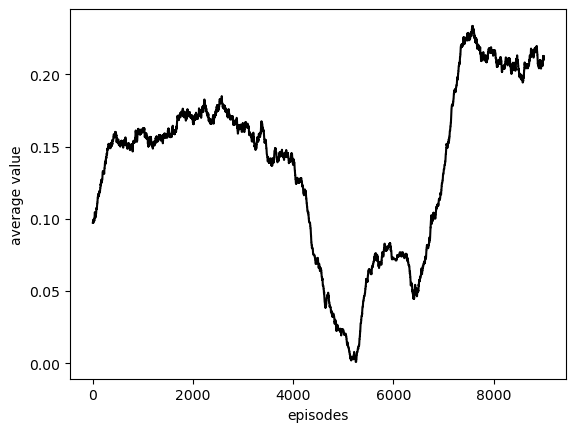

In [63]:
        
with open("./training.log", 'r') as f:
    lines = f.readlines()

values = [float(line.split(",")[-1]) for line in lines]
            
#
    
values = np.array(values)
    
delta = 1000
avg_rewards = []
fig, ax = plt.subplots()
for i in range(values.shape[0] - delta):
    avg_rewards.append(np.mean(values[i:i+delta]))
    
ax.plot(range(len(avg_rewards)), avg_rewards, '-', c='black')
ax.set_xlabel("episodes")
ax.set_ylabel("average value")
fig.savefig("./cumulative_average_reward.png", bbox_inches='tight')
    

We can test the model

In [56]:
init_position = np.array([300, 140])
agent.env.init_position = init_position

steps, total_reward, total_value, path, n_zeros, terminated = agent.step(horizon = 50, callback = None, clip_position = False, test=True) 

In [57]:
print("Converged: {}\tSteps: {}".format(terminated, steps))

Converged: False	Steps: 50


In [58]:
view_data = data.copy()
view_data[view_data < 3e-6] = 1e-20
view_data = np.log10(view_data)

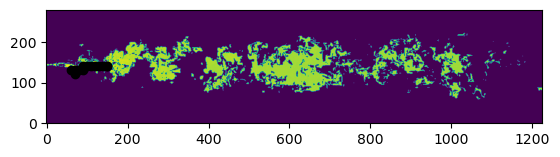

In [50]:
fig, ax = plt.subplots()
ax.imshow(view_data[:, :, 0].T, origin='lower', cmap='viridis')
for i in range(len(path) - 1):
    pos, pos_next = path[i], path[i + 1]
    ax.plot(pos[0], pos[1], 'x', c='black')